In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)

In [2]:
df = pd.read_csv("../data/online_retail_clean.csv")
print(df.columns.tolist())
print(df.head(3))
print(df.dtypes)
print(df.shape)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Month', 'Sales']
   Invoice StockCode                          Description  Quantity  \
0   489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1   489434    79323P                   PINK CHERRY LIGHTS        12   
2   489434    79323W                  WHITE CHERRY LIGHTS        12   

           InvoiceDate  Price  Customer ID         Country    Month  Sales  
0  2009-12-01 07:45:00   6.95        13085  United Kingdom  2009-12   83.4  
1  2009-12-01 07:45:00   6.75        13085  United Kingdom  2009-12   81.0  
2  2009-12-01 07:45:00   6.75        13085  United Kingdom  2009-12   81.0  
Invoice          int64
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID      int64
Country         object
Month           object
Sales          float64
dtype: object
(400916, 10)


In [3]:
df = df.rename(columns={
    "Invoice": "InvoiceNo",
    "Customer ID": "CustomerID",
    "Price": "UnitPrice",
})
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [4]:
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(df["InvoiceDate"].min(), df["InvoiceDate"].max())
print("Customers:", df["CustomerID"].nunique())

2009-12-01 07:45:00 2010-12-09 20:01:00
Customers: 4312


In [5]:
last_date  = df["InvoiceDate"].max()
window_end = last_date + pd.Timedelta(days=1)
cutoff     = window_end - pd.DateOffset(months=3)

obs    = df[df["InvoiceDate"] <  cutoff]   # features yahan se
future = df[df["InvoiceDate"] >= cutoff]   # label yahan se

print("Cutoff:", cutoff)
print("Observation rows:", len(obs), "| Future rows:", len(future))

Cutoff: 2010-09-10 20:01:00
Observation rows: 253543 | Future rows: 147373


In [6]:
feat = obs.groupby("CustomerID").agg(
    last_purchase=("InvoiceDate", "max"),
    first_purchase=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    UniqueProducts=("StockCode", "nunique"),
).reset_index()

feat["Recency"] = (cutoff - feat["last_purchase"]).dt.days
feat["Tenure"] = (cutoff - feat["first_purchase"]).dt.days
feat["AvgOrderValue"] = feat["Monetary"] / feat["Frequency"]
feat = feat.drop(columns=["last_purchase", "first_purchase"])
feat.head()

,CustomerID,Frequency,Monetary,UniqueProducts,Recency,Tenure,AvgOrderValue
0,12346,11,372.86,26,74,270,33.896364
1,12349,2,1268.52,47,115,134,634.260000
2,12355,1,488.21,22,112,112,488.210000
3,12358,2,1697.93,34,95,276,848.965000
4,12359,5,2012.03,82,80,279,402.406000


In [7]:
active_in_future = set(future["CustomerID"].unique())
feat["Churn"] = (~feat["CustomerID"].isin(active_in_future)).astype(int)

print(feat["Churn"].value_counts())
print(feat["Churn"].value_counts(normalize=True))

Churn
0    1942
1    1435
Name: count, dtype: int64
Churn
0    0.575067
1    0.424933
Name: proportion, dtype: float64


In [8]:
X = feat.drop(columns=["CustomerID", "Churn"])
y = feat["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)

======================================== Logistic Regression
              precision    recall  f1-score   support

           0       0.75      0.59      0.66       389
           1       0.57      0.74      0.64       287

    accuracy                           0.65       676
   macro avg       0.66      0.66      0.65       676
weighted avg       0.68      0.65      0.65       676

ROC-AUC: 0.7301


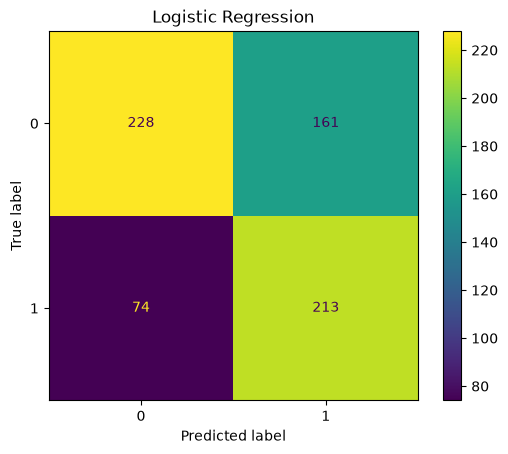

======================================== Random Forest
              precision    recall  f1-score   support

           0       0.72      0.68      0.70       389
           1       0.60      0.64      0.62       287

    accuracy                           0.66       676
   macro avg       0.66      0.66      0.66       676
weighted avg       0.67      0.66      0.66       676

ROC-AUC: 0.7142


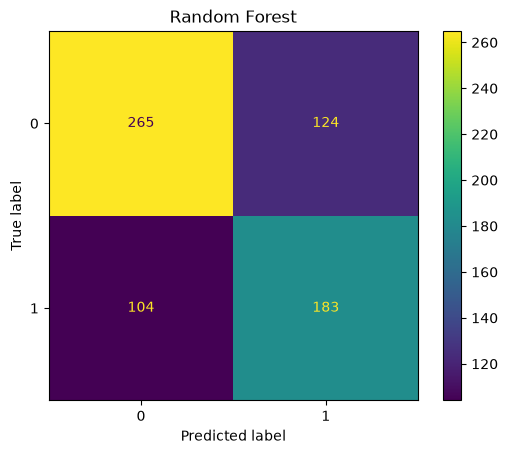

In [9]:
for name, m in models.items():
    pred  = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    print("=" * 40, name)
    print(classification_report(y_test, pred))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name)
    plt.show()

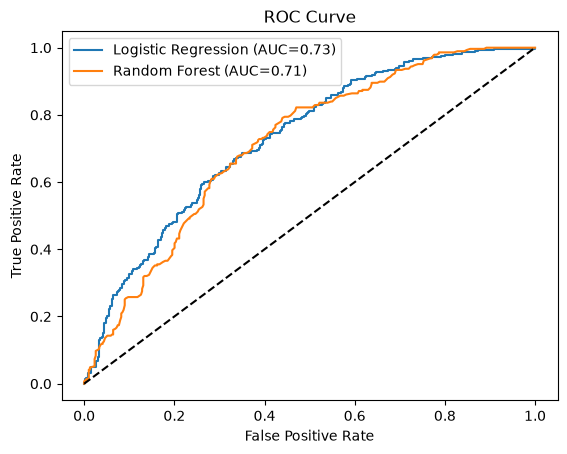

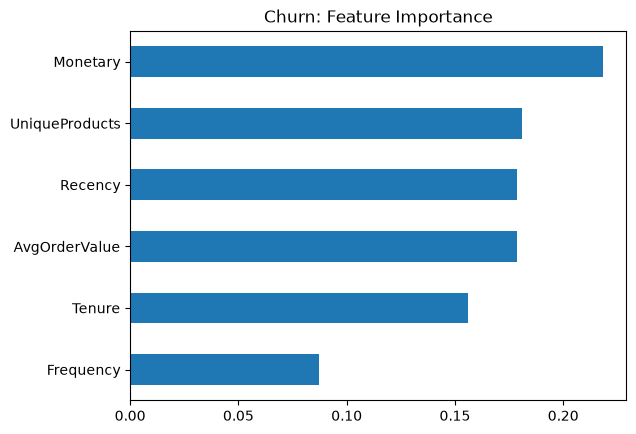

In [10]:
plt.figure()
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(); plt.title("ROC Curve"); plt.show()

rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(
    kind="barh", title="Churn: Feature Importance")
plt.show()

In [11]:
best_model = models["Random Forest"]
joblib.dump(best_model, "../models/churn_model.pkl")
joblib.dump(list(X.columns), "../models/churn_features.pkl")

['../models/churn_features.pkl']

In [12]:
feat["ChurnProbability"] = best_model.predict_proba(X)[:, 1]
feat["RiskLevel"] = pd.cut(
    feat["ChurnProbability"], bins=[0, 0.33, 0.66, 1.0],
    labels=["Low", "Medium", "High"], include_lowest=True)

feat.to_csv("../data/churn_predictions.csv", index=False)
print(feat["RiskLevel"].value_counts())

RiskLevel
Low       1676
High      1315
Medium     386
Name: count, dtype: int64
